# Exponential Distribution

Companion notebook for the [exponential distribution note](../../notes/random_variables_and_distributions/continuous/exponential_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/exponential_distribution.md).

$X\sim\text{Exp}(\lambda)$ with rate $\lambda$:

$$f(x)=\lambda e^{-\lambda x},\quad F(x)=1-e^{-\lambda x},\quad E[X]=\frac1\lambda,\quad \operatorname{Var}(X)=\frac1{\lambda^2}\ (x\ge0).$$

`scipy.stats.expon` uses `scale = 1/rate`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

In [2]:
class ExponentialDistribution:
    def __init__(self, rate):
        self.rate = rate

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        return np.where(x >= 0, self.rate * np.exp(-self.rate * x), 0.0)

    def cdf(self, x):
        x = np.asarray(x, dtype=float)
        return np.where(x >= 0, 1 - np.exp(-self.rate * x), 0.0)

## Check against `scipy.stats`

In [3]:
lam1, lam2 = 0.5, 1.5
x = np.linspace(0, 10, 1000)
d1, d2 = ExponentialDistribution(lam1), ExponentialDistribution(lam2)

pdf1, pdf2 = stats.expon.pdf(x, scale=1 / lam1), stats.expon.pdf(x, scale=1 / lam2)
cdf1, cdf2 = stats.expon.cdf(x, scale=1 / lam1), stats.expon.cdf(x, scale=1 / lam2)
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("CDF matches:", np.allclose(d1.cdf(x), cdf1), np.allclose(d2.cdf(x), cdf2))

PDF matches: True True
CDF matches: True True


## Shape of the PDF and CDF

The density is largest at 0 and decays monotonically; the larger rate $\lambda=1.5$ concentrates mass near 0 (mean $0.67$) while $\lambda=0.5$ has a heavy tail (mean $2$).

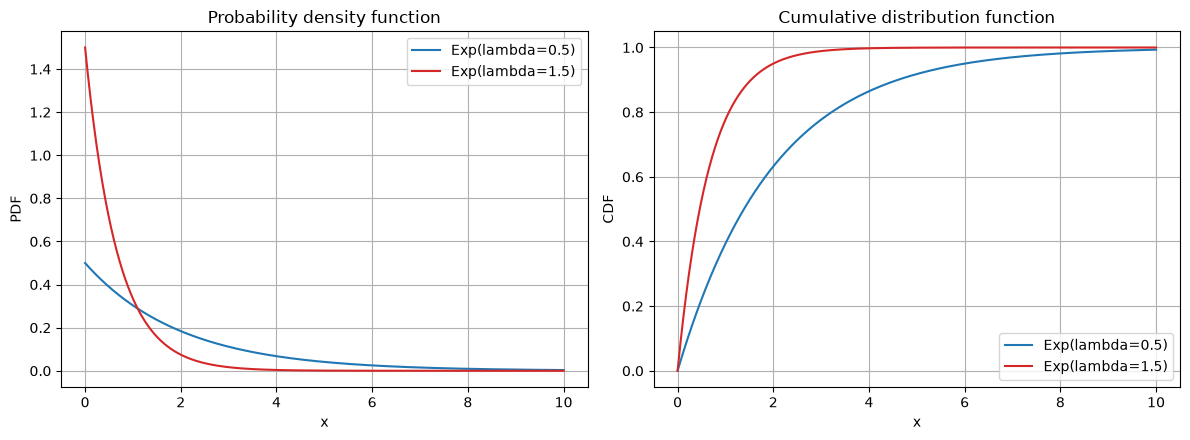

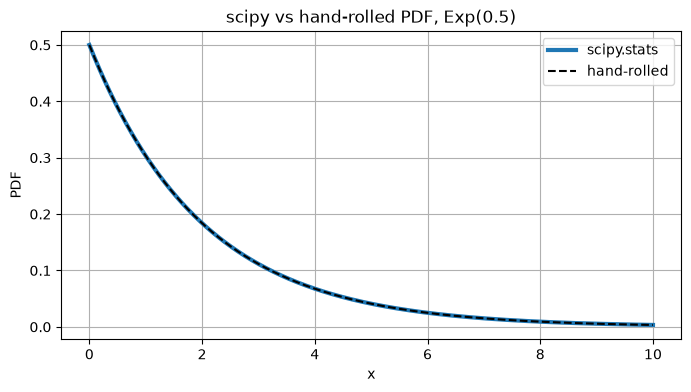

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"Exp(lambda={lam1})", pdf2, cdf2, f"Exp(lambda={lam2})")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, Exp(0.5)")

## Worked example: component lifetime and memorylessness

From the note: mean time to failure 5 years, so $\lambda=1/5$. We also check the memoryless property numerically: $P(X>s+t\mid X>s)=P(X>t)$.

In [5]:
life = ExponentialDistribution(1 / 5)
print(f"P(X < 1)  = {life.cdf(1.0):.4f}")
print(f"P(X > 10) = {1 - life.cdf(10.0):.4f}   e^-2 = {math.exp(-2):.4f}")

s, t = 3.0, 4.0
cond = (1 - life.cdf(s + t)) / (1 - life.cdf(s))
print(f"P(X > {s + t:.0f} | X > {s:.0f}) = {cond:.4f}   P(X > {t:.0f}) = {1 - life.cdf(t):.4f}")
print(f"median = ln 2 / lambda = {math.log(2) * 5:.3f}  (mean = 5)")

P(X < 1)  = 0.1813
P(X > 10) = 0.1353   e^-2 = 0.1353
P(X > 7 | X > 3) = 0.4493   P(X > 4) = 0.4493
median = ln 2 / lambda = 3.466  (mean = 5)


## Simulation versus theory

By inverse-transform sampling, $-\ln(U)/\lambda\sim\text{Exp}(\lambda)$ for $U\sim\text{Uniform}(0,1)$. We use this to generate a sample and compare with theory.

mean: sample 1.9986  theory 2.0000
var : sample 4.0317  theory 4.0000


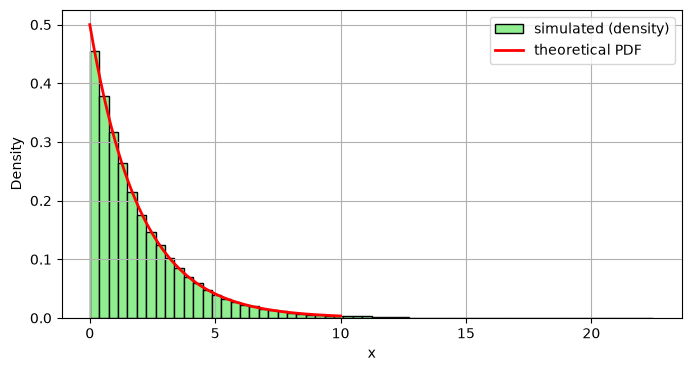

In [6]:
sample = -np.log(rng.uniform(size=100_000)) / lam1
print(f"mean: sample {sample.mean():.4f}  theory {1 / lam1:.4f}")
print(f"var : sample {sample.var():.4f}  theory {1 / lam1**2:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(sample, bins=60, density=True, color="lightgreen", edgecolor="black", label="simulated (density)")
plt.plot(x, stats.expon.pdf(x, scale=1 / lam1), "r-", linewidth=2, label="theoretical PDF")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* The exponential is the waiting time between events of a Poisson process, with a constant hazard rate.
* It is memoryless, and its median is $\ln 2$ times its mean.
* Inverse-transform sampling turns a uniform draw into an exponential one.